In [1]:
from itertools import product
from pathlib import Path

import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from dynamical_systems.analysis.jacobian import jacobian
from dynamical_systems.continuous import Lorenz63, Lorenz96, solve_ode
from dynamical_systems.metrics import (
    cosine_similarity as cosine_similarity,
    maximum_mean_discrepancy as maximum_mean_discrepancy,
    root_mean_squared_error as root_mean_squared_error,
    sinkhorn_divergence as sinkhorn_divergence,
)
from dynamical_systems.metrics.statistical import (
    mean_spectral_hellinger_distance,
)
from dynamical_systems.transforms import TransformedODE
from dynamics_discovery.data import TimeSeriesDataset
from dynamics_discovery.io import load_model
from einops import rearrange, reduce
from jaxtyping import Array, Float
from tqdm import tqdm


plt.style.use("matplotlib_utils.styles.dash_gridded")
jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_device", jax.devices("gpu")[0])

datadir = Path("../../data")
ckptdir = Path("../../results/revised")
downsample = 2
time_slice = slice(0, 500 * downsample, downsample)
noise = 0.01

SYSTEM_NAME_DICT = {
    "lorenz63": "Lorenz63",
    "lorenz96_6d": "Lorenz96 (6d)",
    "lorenz96_18d": "Lorenz96 (18d)",
    "lorenz96_54d": "Lorenz96 (54d)",
}

ODE_DICT = {
    "lorenz63": Lorenz63(),
    "lorenz96_6d": Lorenz96(dim=6),
    "lorenz96_18d": Lorenz96(dim=18),
    "lorenz96_54d": Lorenz96(dim=54),
}

In [2]:
system_name = "lorenz63"

_, transform_train = TimeSeriesDataset.from_hdf5(
    datadir / f"{system_name}_train.hdf5", time_slice=time_slice
).standardize()

dataset_test = TimeSeriesDataset.from_hdf5(
    datadir / f"{system_name}_test.hdf5", time_slice=time_slice
).apply_transform(transform_train)

dataset_test_long = TimeSeriesDataset.from_hdf5(
    datadir / f"{system_name}_test.hdf5", time_slice=slice(0, None, downsample)
).apply_transform(transform_train)

In [3]:
@eqx.filter_jit
def solve_batch(model, t, u0_batched):
    def _solve(u0_):
        u = solve_ode(model, t, u0_, rtol=1e-4, atol=1e-6, max_steps=None)
        return u

    return eqx.filter_vmap(_solve)(u0_batched)


def normalized_rmse(
    u_pred: Float[Array, "... time dim"], u_true: Float[Array, "... time dim"]
) -> Float[Array, " time"]:
    vars = reduce(u_true, "... c -> c", jnp.var)
    rmses: Float[Array, "... time dim"] = jnp.sqrt(
        jnp.mean((u_pred - u_true) ** 2 / vars, axis=-1)
    )
    return reduce(rmses, "... t -> t", "mean")


jacobian_batch = eqx.filter_vmap(
    lambda model, x: jacobian(model, 0.0, x), in_axes=(None, 0)
)


def rel_jac_error(jac_pred, jac_true):
    jac_norm = jnp.linalg.norm(jac_true, axis=(-2, -1), ord="fro")
    jac_err_norm = jnp.linalg.norm(jac_pred - jac_true, axis=(-2, -1), ord="fro")
    return jac_err_norm / jac_norm


## DySLIM

(-5.0, 5.0)

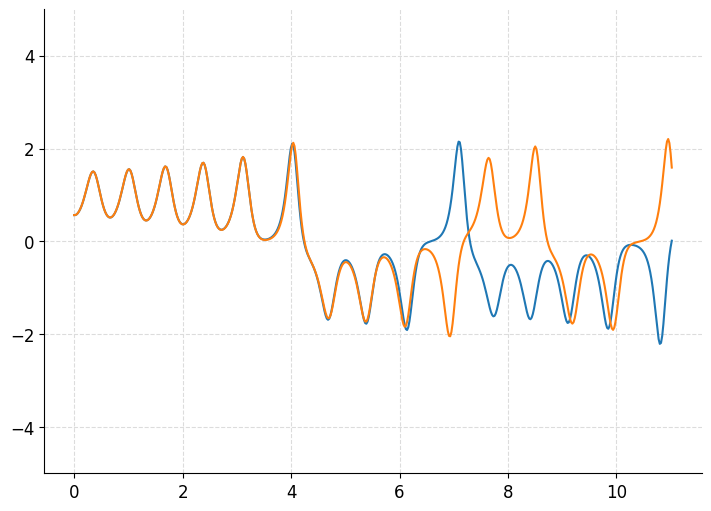

In [4]:
model = load_model(
    ckptdir
    / system_name
    / "dyslim"
    / f"lambda_1={0}_lambda_2={1}/lr=0.001_noise=0.01_key=0"
)
u_pred = solve_batch(model, dataset_test.t[0], dataset_test.u[:, 0])

fig, ax = plt.subplots(1, 1, figsize=(7, 5))
ax.plot(dataset_test.t[0], dataset_test.u[0, :, 0])
ax.plot(dataset_test.t[0], u_pred[0, :, 0])
ax.set_ylim((-5, 5))

12it [00:09,  1.24it/s]


Text(0.5, 0.98, 'Lorenz63 DySLIM hyperparameter sweep: (lambda_1, lambda_2)')

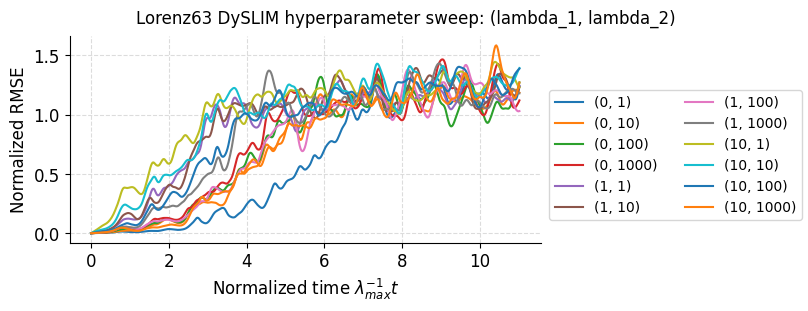

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(8, 3))
for l1, l2 in tqdm(product((0, 1, 10), (1, 10, 100, 1000))):
    model = load_model(
        ckptdir
        / system_name
        / "dyslim"
        / f"lambda_1={l1}_lambda_2={l2}/lr=0.001_noise=0.01_key=0"
    )
    u_pred = solve_batch(model, dataset_test.t[0], dataset_test.u[:, 0])

    ax.plot(
        dataset_test.t[0],
        normalized_rmse(u_pred, dataset_test.u),
        label=f"({l1}, {l2})",
    )

fig.legend(loc="outside center right", ncols=2, fontsize="small")
ax.set_xlabel(r"Normalized time $\lambda_{max}^{-1}t$")
ax.set_ylabel("Normalized RMSE")
fig.suptitle(
    f"{SYSTEM_NAME_DICT[system_name]} DySLIM hyperparameter sweep: (lambda_1, lambda_2)",
    fontsize="medium",
)

In [6]:
u_test_flat = rearrange(dataset_test.u, "b t c->(b t) c")
jac_true = jacobian_batch(
    TransformedODE(ODE_DICT[system_name], transform_train),
    u_test_flat,
)


jac_err_list = []
for l1, l2 in tqdm(product((0, 1, 10), (1, 10, 100, 1000))):
    model = load_model(
        ckptdir
        / system_name
        / "dyslim"
        / f"lambda_1={l1}_lambda_2={l2}/lr=0.001_noise=0.01_key=0"
    )
    jac_pred = jacobian_batch(
        model,
        u_test_flat,
    )
    jac_err_list.append(jnp.log10(rel_jac_error(jac_pred, jac_true)))


12it [00:01, 10.77it/s]


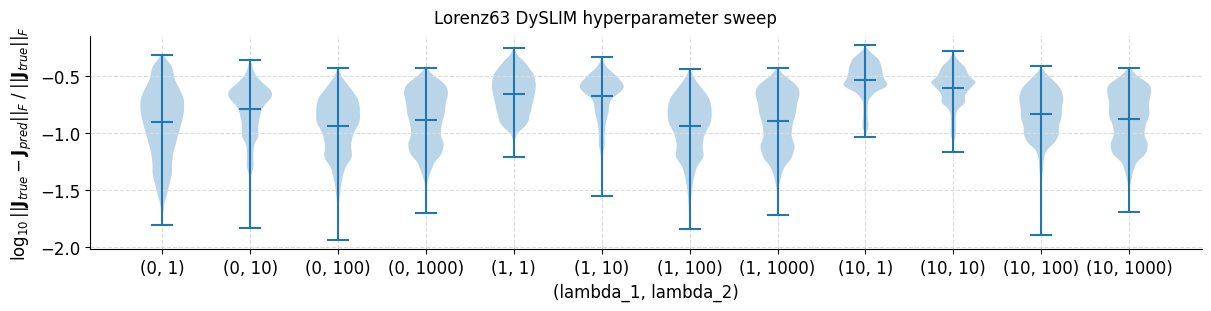

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(12, 3))
ax.violinplot(jac_err_list, showmeans=True)

ax.set_xlabel("(lambda_1, lambda_2)")
ax.set_ylabel(
    r"$\log_{10}||\mathbf{J}_{true}-\mathbf{J}_{pred}||_F\;/\;||\mathbf{J}_{true}||_F$"
)
fig.suptitle(
    f"{SYSTEM_NAME_DICT[system_name]} DySLIM hyperparameter sweep",
    fontsize="medium",
)
ax.set_xticks(
    np.arange(1, len(jac_err_list) + 1),
    labels=list(product((0, 1, 10), (1, 10, 100, 1000))),
)

In [8]:
hellingers = []
for l1, l2 in tqdm(product((0, 1, 10), (1, 10, 100, 1000))):
    model = load_model(
        ckptdir
        / system_name
        / "dyslim"
        / f"lambda_1={l1}_lambda_2={l2}/lr=0.001_noise=0.01_key=0"
    )
    u_pred_long = solve_batch(model, dataset_test_long.t[0], dataset_test_long.u[:, 0])
    hellingers.append(
        jnp.mean(
            eqx.filter_vmap(mean_spectral_hellinger_distance)(
                u_pred_long, dataset_test_long.u
            )
        )
    )

12it [00:55,  4.63s/it]


Text(0.5, 0.98, 'Lorenz63 DySLIM hyperparameter sweep')

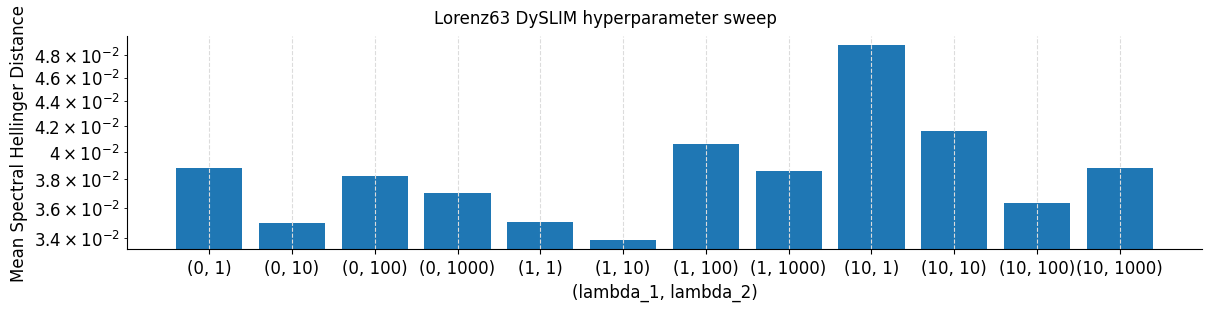

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(12, 3))
ax.bar(np.arange(1, len(hellingers) + 1), hellingers)
ax.set_yscale("log", base=10)
ax.set_xticks(
    np.arange(1, len(hellingers) + 1),
    labels=list(product((0, 1, 10), (1, 10, 100, 1000))),
)
ax.set_xlabel("(lambda_1, lambda_2)")
ax.set_ylabel("Mean Spectral Hellinger Distance")
fig.suptitle(
    f"{SYSTEM_NAME_DICT[system_name]} DySLIM hyperparameter sweep",
    fontsize="medium",
)

## Neighborhood

100%|██████████| 9/9 [00:05<00:00,  1.61it/s]


Text(0.5, 0.98, 'Lorenz63 Neighborhood hyperparameter sweep: (num_neighbors, weight)')

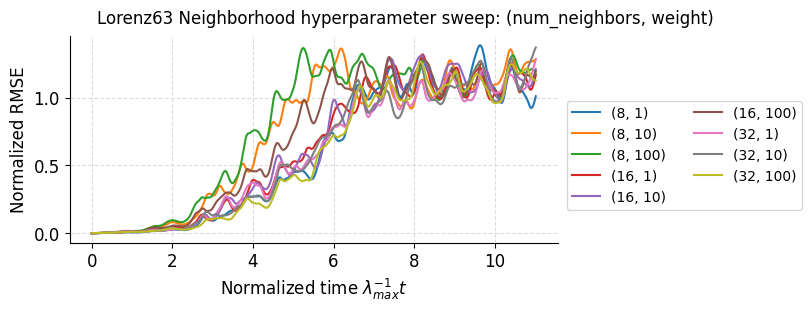

In [10]:
hyperparam_list = list(product((8, 16, 32), (1, 10, 100)))
fig, ax = plt.subplots(1, 1, figsize=(8, 3))
for l1, l2 in tqdm(hyperparam_list):
    model = load_model(
        ckptdir
        / system_name
        / "neighborhood"
        / f"num_neighbors={l1}_weight={l2}/lr=0.001_noise=0.01_key=0"
    )
    u_pred = solve_batch(model, dataset_test.t[0], dataset_test.u[:, 0])

    ax.plot(
        dataset_test.t[0],
        normalized_rmse(u_pred, dataset_test.u),
        label=f"({l1}, {l2})",
    )
fig.legend(loc="outside center right", ncols=2, fontsize="small")
ax.set_xlabel(r"Normalized time $\lambda_{max}^{-1}t$")
ax.set_ylabel("Normalized RMSE")
fig.suptitle(
    f"{SYSTEM_NAME_DICT[system_name]} Neighborhood hyperparameter sweep: (num_neighbors, weight)",
    fontsize="medium",
)


In [11]:
u_test_flat = rearrange(dataset_test.u, "b t c->(b t) c")
jac_true = jacobian_batch(
    TransformedODE(ODE_DICT[system_name], transform_train),
    u_test_flat,
)


jac_err_list = []
for l1, l2 in tqdm(hyperparam_list):
    model = load_model(
        ckptdir
        / system_name
        / "neighborhood"
        / f"num_neighbors={l1}_weight={l2}/lr=0.001_noise=0.01_key=0"
    )
    jac_pred = jacobian_batch(
        model,
        u_test_flat,
    )
    jac_err_list.append(jnp.log10(rel_jac_error(jac_pred, jac_true)))


100%|██████████| 9/9 [00:00<00:00, 32.35it/s]


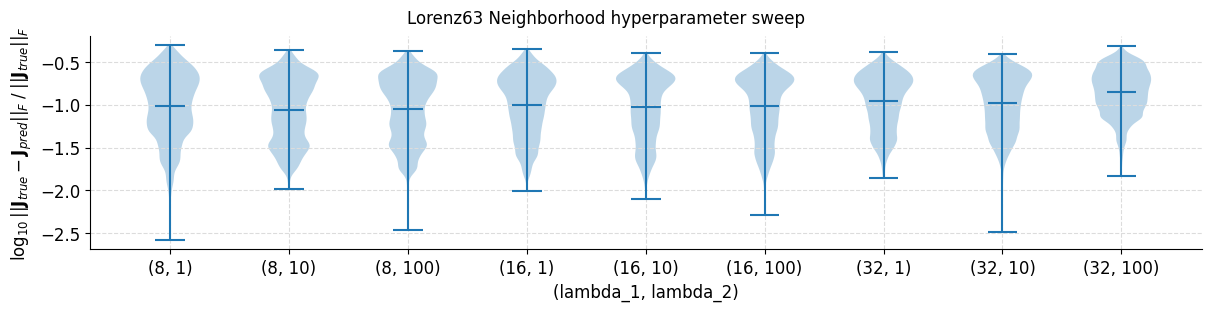

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(12, 3))
ax.violinplot(jac_err_list, showmeans=True)

ax.set_xlabel("(lambda_1, lambda_2)")
ax.set_ylabel(
    r"$\log_{10}||\mathbf{J}_{true}-\mathbf{J}_{pred}||_F\;/\;||\mathbf{J}_{true}||_F$"
)
fig.suptitle(
    f"{SYSTEM_NAME_DICT[system_name]} Neighborhood hyperparameter sweep",
    fontsize="medium",
)
ax.set_xticks(
    np.arange(1, len(jac_err_list) + 1),
    labels=hyperparam_list,
)

In [13]:
hellingers = []
for l1, l2 in tqdm(hyperparam_list):
    model = load_model(
        ckptdir
        / system_name
        / "neighborhood"
        / f"num_neighbors={l1}_weight={l2}/lr=0.001_noise=0.01_key=0"
    )
    u_pred_long = solve_batch(model, dataset_test_long.t[0], dataset_test_long.u[:, 0])
    hellingers.append(
        jnp.mean(
            eqx.filter_vmap(mean_spectral_hellinger_distance)(
                u_pred_long, dataset_test_long.u
            )
        )
    )

100%|██████████| 9/9 [00:38<00:00,  4.24s/it]


Text(0.5, 0.98, 'Lorenz63 Neighborhood hyperparameter sweep')

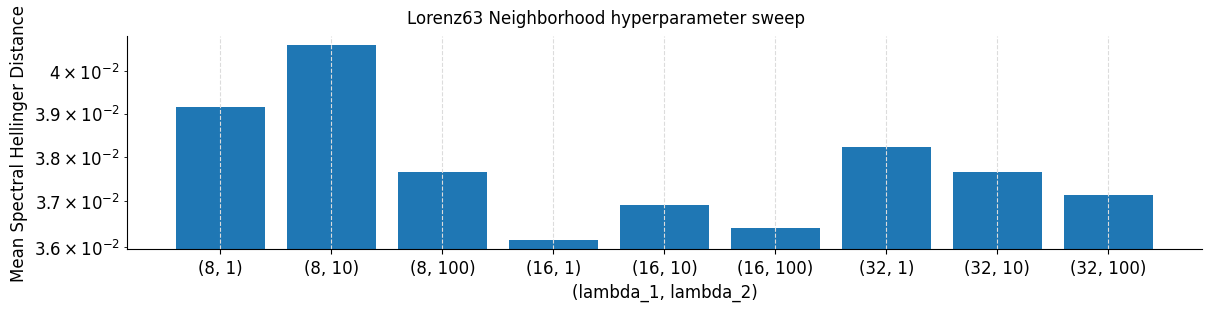

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(12, 3))
ax.bar(np.arange(1, len(hellingers) + 1), hellingers)
ax.set_yscale("log", base=10)

ax.set_xticks(
    np.arange(1, len(hellingers) + 1),
    labels=hyperparam_list,
)
ax.set_xlabel("(lambda_1, lambda_2)")
ax.set_ylabel("Mean Spectral Hellinger Distance")
fig.suptitle(
    f"{SYSTEM_NAME_DICT[system_name]} Neighborhood hyperparameter sweep",
    fontsize="medium",
)

## Efficient Neighborhood

100%|██████████| 12/12 [00:02<00:00,  4.67it/s]


Text(0.5, 0.98, 'Lorenz63 Efficient Neighborhood hyperparameter sweep: (lambda_1, lambda_2)')

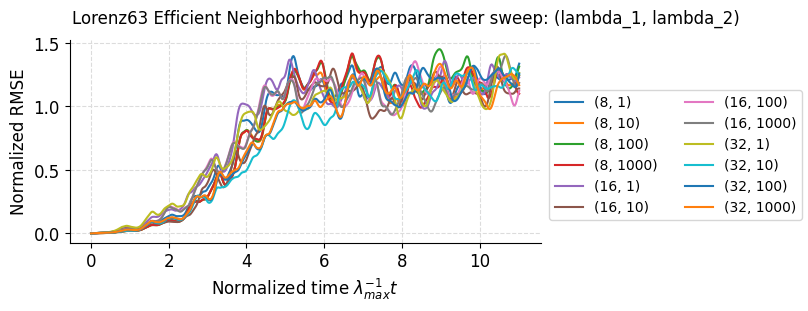

In [15]:
hyperparam_list = list(product((8, 16, 32), (1, 10, 100, 1000)))

fig, ax = plt.subplots(1, 1, figsize=(8, 3))
for l1, l2 in tqdm(hyperparam_list):
    model = load_model(
        ckptdir
        / system_name
        / "efficient_neighborhood"
        / f"num_neighbors={l1}_weight={l2}/lr=0.001_noise=0.01_key=0"
    )
    u_pred = solve_batch(model, dataset_test.t[0], dataset_test.u[:, 0])

    ax.plot(
        dataset_test.t[0],
        normalized_rmse(u_pred, dataset_test.u),
        label=f"({l1}, {l2})",
    )

fig.legend(loc="outside center right", ncols=2, fontsize="small")
ax.set_xlabel(r"Normalized time $\lambda_{max}^{-1}t$")
ax.set_ylabel("Normalized RMSE")
fig.suptitle(
    f"{SYSTEM_NAME_DICT[system_name]} Efficient Neighborhood hyperparameter sweep: (lambda_1, lambda_2)",
    fontsize="medium",
)

In [16]:
u_test_flat = rearrange(dataset_test.u, "b t c->(b t) c")
jac_true = jacobian_batch(
    TransformedODE(ODE_DICT[system_name], transform_train),
    u_test_flat,
)


jac_err_list = []
for l1, l2 in tqdm(hyperparam_list):
    model = load_model(
        ckptdir
        / system_name
        / "efficient_neighborhood"
        / f"num_neighbors={l1}_weight={l2}/lr=0.001_noise=0.01_key=0"
    )
    jac_pred = jacobian_batch(
        model,
        u_test_flat,
    )
    jac_err_list.append(jnp.log10(rel_jac_error(jac_pred, jac_true)))


100%|██████████| 12/12 [00:00<00:00, 32.36it/s]


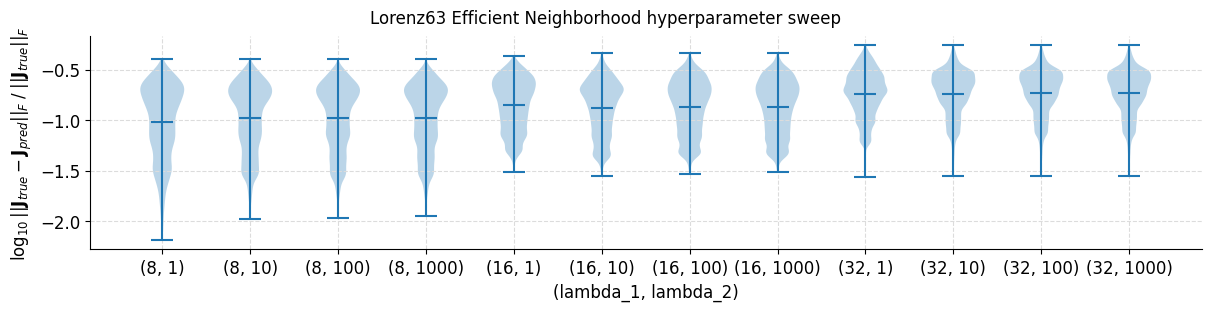

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(12, 3))
ax.violinplot(jac_err_list, showmeans=True)

ax.set_xlabel("(lambda_1, lambda_2)")
ax.set_ylabel(
    r"$\log_{10}||\mathbf{J}_{true}-\mathbf{J}_{pred}||_F\;/\;||\mathbf{J}_{true}||_F$"
)
fig.suptitle(
    f"{SYSTEM_NAME_DICT[system_name]} Efficient Neighborhood hyperparameter sweep",
    fontsize="medium",
)
ax.set_xticks(
    np.arange(1, len(jac_err_list) + 1),
    labels=hyperparam_list,
)

In [18]:
hellingers = []
for l1, l2 in tqdm(hyperparam_list):
    model = load_model(
        ckptdir
        / system_name
        / "efficient_neighborhood"
        / f"num_neighbors={l1}_weight={l2}/lr=0.001_noise=0.01_key=0"
    )
    u_pred_long = solve_batch(model, dataset_test_long.t[0], dataset_test_long.u[:, 0])
    hellingers.append(
        jnp.mean(
            eqx.filter_vmap(mean_spectral_hellinger_distance)(
                u_pred_long, dataset_test_long.u
            )
        )
    )

100%|██████████| 12/12 [01:13<00:00,  6.09s/it]


Text(0.5, 0.98, 'Lorenz63 Efficient Neighborhood hyperparameter sweep')

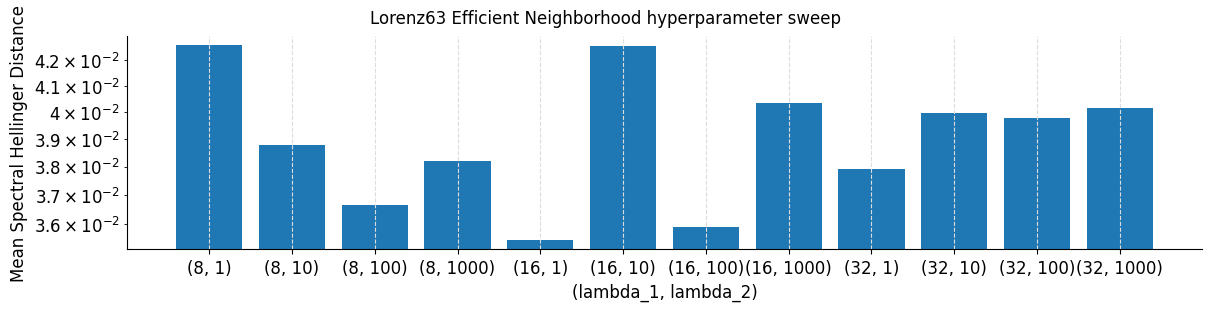

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(12, 3))
ax.bar(np.arange(1, len(hellingers) + 1), hellingers)
ax.set_yscale("log", base=10)

ax.set_xticks(
    np.arange(1, len(hellingers) + 1),
    labels=hyperparam_list,
)
ax.set_xlabel("(lambda_1, lambda_2)")
ax.set_ylabel("Mean Spectral Hellinger Distance")
fig.suptitle(
    f"{SYSTEM_NAME_DICT[system_name]} Efficient Neighborhood hyperparameter sweep",
    fontsize="medium",
)

In [ ]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt


mmds = []
num_samples = 2 ** jnp.arange(3, 13)
for n in num_samples:
    u = jax.random.normal(jax.random.key(10), shape=(n, 3))
    v = jax.random.normal(jax.random.key(5), shape=(n, 3))
    mmds.append(maximum_mean_discrepancy2(u, v))


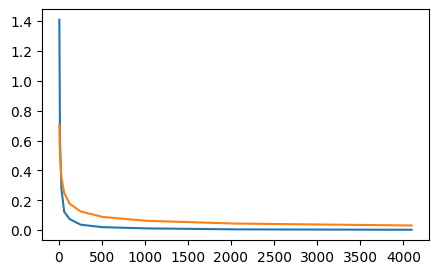

In [61]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.plot(num_samples, jnp.asarray(mmds))
ax.plot(num_samples, 2 / jnp.sqrt(num_samples))

In [37]:
(jnp.log(mmds[0]) - jnp.log(mmds[-1])) / (
    jnp.log(num_samples[0]) - jnp.log(num_samples[-1])
)

Array(-0.989404, dtype=float32)

In [ ]:
from jaxtyping import Array, Float


def kernel(
    x: Float[Array, " D"],
    y: Float[Array, " D"],
    bandwidths: tuple[float, ...] = (0.2, 0.5, 0.9, 1.3),
):
    diff = jnp.sum((x - y) ** 2)
    return sum([a**2 / (a**2 + diff) for a in bandwidths])


# def mmd2(
#     u: Float[Array, "B D"],
#     v: Float[Array, "B D"],
# ) -> Float[Array, ""]:
#     kuu = j

In [47]:
n = 5
u = jax.random.normal(jax.random.key(2), shape=(n, 3))
v = jax.random.normal(jax.random.key(5), shape=(n, 3))

In [49]:
jax.vmap(jax.vmap(kernel))(jnp.expand_dims(u, 0), jnp.expand_dims(v, 1)).shape

ValueError: vmap got inconsistent sizes for array axes to be mapped:
  * one axis had size 1: axis 0 of argument x of type float32[1,5,3];
  * one axis had size 5: axis 0 of argument y of type float32[5,1,3]

In [58]:
@jax.jit
def maximum_mean_discrepancy2(
    x: Float[Array, "batch dim *rest"],
    y: Float[Array, "batch dim *rest"],
    bandwidth: tuple[float, ...] = (0.1, 0.2, 0.5, 0.9, 1.3),
) -> Float[Array, ""]:
    """Maximum Mean Discrepancy. Adapted from the DySLIM source code:
    https://github.com/google-research/swirl-dynamics/blob/main/swirl_dynamics/projects/ergodic/measure_distances.py

    Empirical maximum mean discrepancy. The lower the result the more evidence
    that
    distributions are the same.
    Input arrays are reshaped to dimension: `batch_size x -1`, where `-1`
    indicates that all non-batch dimensions are flattened.
    This implementation was adapted from [1].

    Args:
        x: first sample, distribution P
        y: second sample, distribution Q
        bandwidth: Multiscale levels for the bandwidth.

    Returns:
        mmd value.
    """
    # Samples x and y are of size `batch_size x state_space_dim`, e.g. for Lorenz
    # system `state_space_dim` is `3`, for KS it is `xspan x 1`, for NS it is
    # `h x w x 1`.
    # These arrays are then reshaped to be order two with shape
    # `batch_size x state_space_dim_flattened`.
    n, m = x.shape[0], y.shape[0]
    x = x.reshape((n, -1))
    y = y.reshape((m, -1))
    xx, yy, zz = jnp.matmul(x, x.T), jnp.matmul(y, y.T), jnp.matmul(x, y.T)
    rx = jnp.broadcast_to(jnp.expand_dims(jnp.diag(xx), axis=0), xx.shape)
    ry = jnp.broadcast_to(jnp.expand_dims(jnp.diag(yy), axis=0), yy.shape)

    dxx = rx.T + rx - 2.0 * xx
    dyy = ry.T + ry - 2.0 * yy
    dxy = rx.T + ry - 2.0 * zz

    xx, yy, xy = (jnp.zeros_like(xx), jnp.zeros_like(xx), jnp.zeros_like(xx))

    # Multiscale bandwisth.
    for a in bandwidth:
        xx += a**2 * (a**2 + dxx) ** -1
        yy += a**2 * (a**2 + dyy) ** -1
        xy += a**2 * (a**2 + dxy) ** -1

    # TODO: We may want to use jnp.sqrt here; see [2].
    return (
        jnp.sum(xx) / (n * (n - 1))
        + jnp.sum(yy) / (m * (m - 1))
        - 2 * jnp.sum(xy) / (n * m)
    )
